# EDA on Retail Sales Data

**Name:** Mohini More  
**Organization:** Oasis Infobyte  
**Internship Track:** Data Analytics  
**Task:** Level 1 — Task 1  
**Tools Used:** Python, Pandas, Matplotlib, Seaborn, Jupyter Notebook

## Project Objective

The objective of this project is to perform Exploratory Data Analysis (EDA) on retail sales data to identify sales trends, understand customer demographics, analyze product category performance, and explore relationships between numerical variables. The findings will help generate useful business insights and recommendations.

## 1. Loading and Initial Inspection of the Dataset

In [1]:
## Importing Required Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
## Loading the Dataset
df = pd.read_csv("C:/OASIS Data Analytics Project/retail_sales_dataset.csv")
df

# Display the first five rows of the dataset
df.head()

# Check the number of rows and columns
df.shape

# Check the data types and non-null counts
df.info()

# Check missing values in each column
df.isnull().sum()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

## 2. Descriptive Statistics
In this section, we calculate summary statistics for all numerical variables to understand their central tendency and variability.


In [7]:
# Select all numerical columns
numeric_df = df.select_dtypes(include="number")
numeric_df

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
0,1,34,3,50,150
1,2,26,2,500,1000
2,3,50,1,30,30
3,4,37,1,500,500
4,5,30,2,50,100
...,...,...,...,...,...
995,996,62,1,50,50
996,997,52,3,30,90
997,998,23,4,25,100
998,999,36,3,50,150


In [8]:
# Create a summary table of descriptive statistics
descriptive_stats = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median(),
    "Mode": numeric_df.mode().iloc[0],
    "Standard Deviation": numeric_df.std()
})

descriptive_stats

,Mean,Median,Mode,Standard Deviation
Transaction ID,500.500,500.5,1.0,288.819436
Age,41.392,42.0,43.0,13.681430
Quantity,2.514,3.0,4.0,1.132734
Price per Unit,179.890,50.0,50.0,189.681356
Total Amount,456.000,135.0,50.0,559.997632



## 3. Monthly and Quarterly Sales Trends

In this section, we analyze sales over time to identify monthly and quarterly patterns and changes in sales performance.


In [9]:
# Display the data types of all columns
df.dtypes

Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object


## Monthly Sales Trend

This analysis examines monthly sales performance to identify changes and patterns over time.


In [10]:
# Convert the Date column to datetime format
df["Date"] = pd.to_datetime(df["Date"])
df["Date"].dtype

dtype('<M8[us]')

In [11]:
# Extract the month and year from the transaction date
df["Year_Month"] = df["Date"].dt.to_period("M")
df["Year_Month"] 

0      2023-11
1      2023-02
2      2023-01
3      2023-05
4      2023-05
        ...   
995    2023-05
996    2023-11
997    2023-10
998    2023-12
999    2023-04
Name: Year_Month, Length: 1000, dtype: period[M]

In [12]:
# Calculate total sales for each month
monthly_sales = df.groupby("Year_Month")["Total Amount"].sum()
monthly_sales

Year_Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

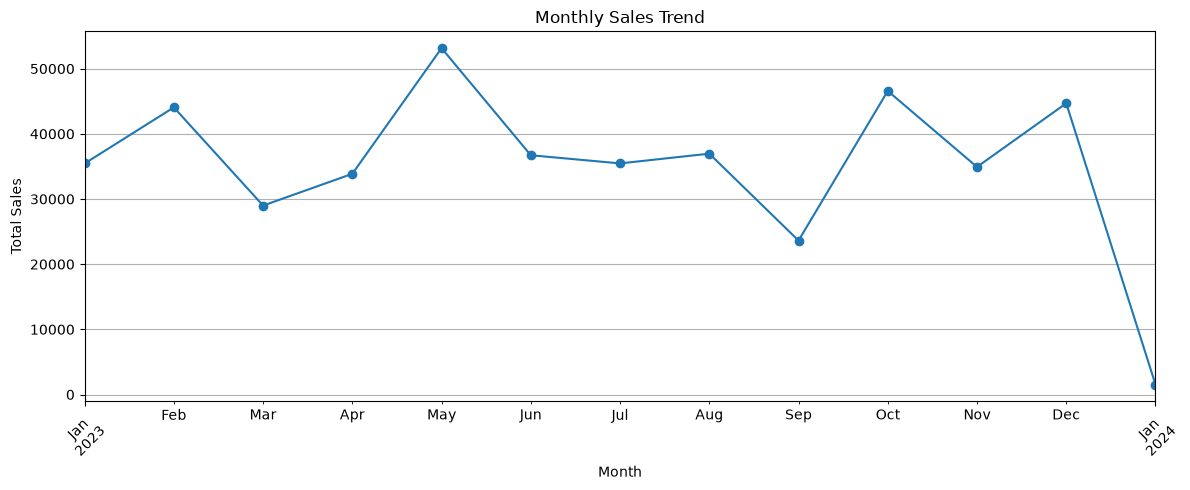

In [13]:
# Plot the monthly sales trend
plt.figure(figsize=(12, 5))
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**Observation: Monthly Sales Trend**

Monthly sales fluctuated throughout 2023. Sales reached their highest level in May 2023, at 53,150, while September 2023 recorded the lowest sales, at 23,620. January 2024 recorded sales of only 1,530; further investigation is needed to determine whether this reflects incomplete data for that month.


## Quarterly Sales Trend

This analysis groups transactions by quarter to identify broader sales patterns and compare performance across quarters.


In [14]:
# Group sales by quarter
df["Year_Quarter"] = df["Date"].dt.to_period("Q")
df["Year_Quarter"] 

0      2023Q4
1      2023Q1
2      2023Q1
3      2023Q2
4      2023Q2
        ...  
995    2023Q2
996    2023Q4
997    2023Q4
998    2023Q4
999    2023Q2
Name: Year_Quarter, Length: 1000, dtype: period[Q-DEC]

In [15]:
# Calculate total sales for each quarter
quarterly_sales = df.groupby("Year_Quarter")["Total Amount"].sum()
quarterly_sales 

Year_Quarter
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64

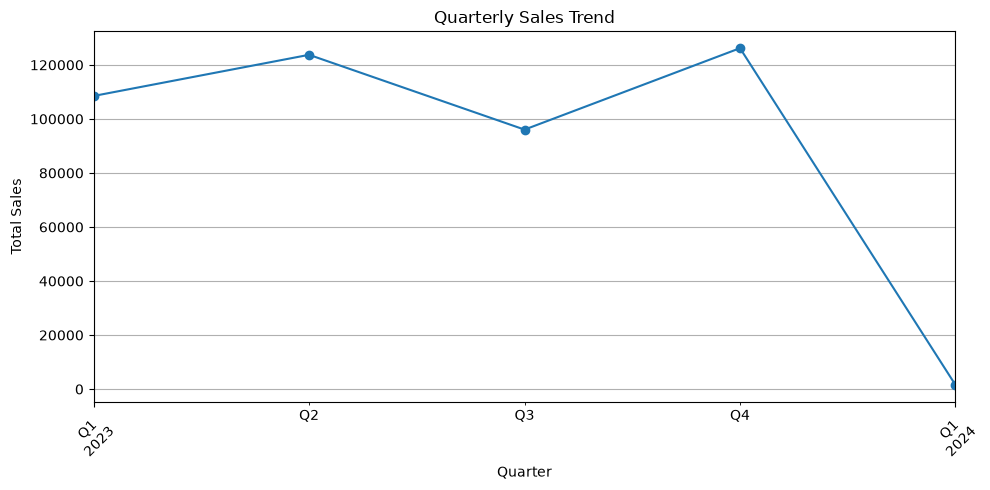

In [16]:
# Create a quarterly sales trend chart
plt.figure(figsize=(10, 5))

quarterly_sales.plot(kind="line", marker="o")

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

**Observation: Quarterly Sales Trend**

Quarterly sales fluctuated during 2023. The highest sales were recorded in Q4 2023, totaling 126,190, while Q3 2023 had the lowest quarterly sales, at 96,045. Sales increased from Q3 to Q4. The Q1 2024 total was only 1,530, so the available data for this quarter should be checked before making a direct comparison with the full quarters of 2023.

## 4. Customer Demographics Analysis
This section will help us understand the age groups and gender distribution of customers.

In [3]:
##Calculate the customer age-group distribution.

# Create age groups

df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=["Under 20", "21-30", "31-40", "41-50", "51-60", "Above 60"],
    right=False
)
df["Age Group"] 

0         31-40
1         21-30
2         51-60
3         31-40
4         31-40
         ...   
995    Above 60
996       51-60
997       21-30
998       31-40
999       41-50
Name: Age Group, Length: 1000, dtype: category
Categories (6, str): ['Under 20' < '21-30' < '31-40' < '41-50' < '51-60' < 'Above 60']

In [4]:
# Count records in each age group
age_group_counts = df["Age Group"].value_counts().sort_index()
age_group_counts

Age Group
Under 20     42
21-30       209
31-40       191
41-50       222
51-60       221
Above 60    115
Name: count, dtype: int64

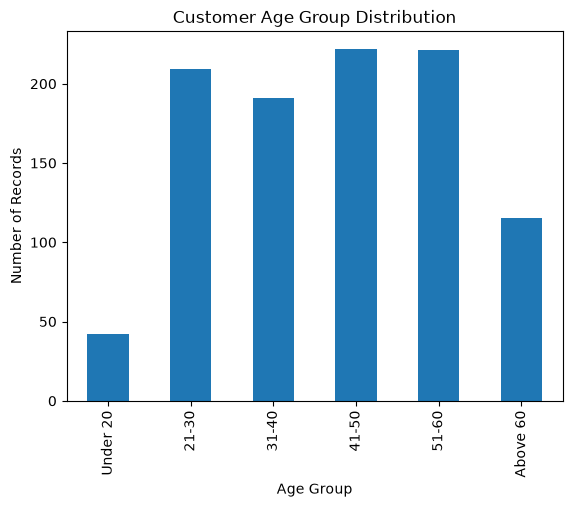

In [5]:
# The age-group chart
age_group_counts.plot(kind="bar", title="Customer Age Group Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Records")
plt.show()


**Observation: Customer Age Group Distribution**

The bar chart shows the distribution of customer records across different age groups. The age group with the tallest bar has the highest number of records, while the age group with the shortest bar has the lowest number of records.


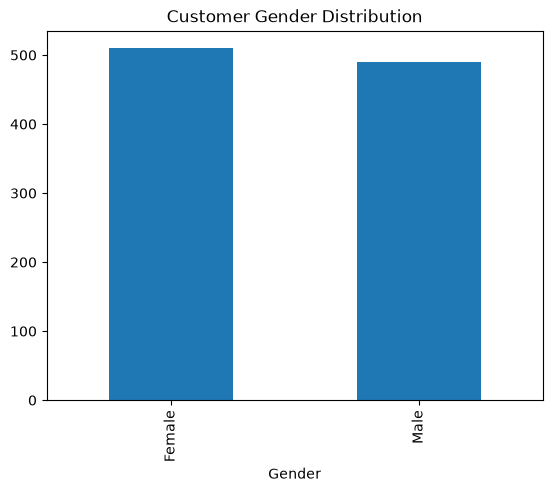

In [7]:
## Gender Distribution

gender_counts = df["Gender"].value_counts()
gender_counts.plot(kind="bar", title="Customer Gender Distribution")
plt.show()


**Observation: Customer Gender Distribution**

The bar chart shows the distribution of customer records by gender. It helps identify which gender group accounts for a larger share of the transactions and whether the distribution is relatively balanced or uneven. This information can help the business understand its customer demographics and plan targeted marketing strategies.



## 5. Product Analysis
Note: Dataset contains Product Category, Quantity, and Total Amount, but it doesn't have an individual product-name column. So we'll analyze product categories and sales quantities without pretending the dataset contains individual product names.


In [23]:
# Revenue by Product Category

category_sales = df.groupby("Product Category")["Total Amount"].sum()
category_sales


Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

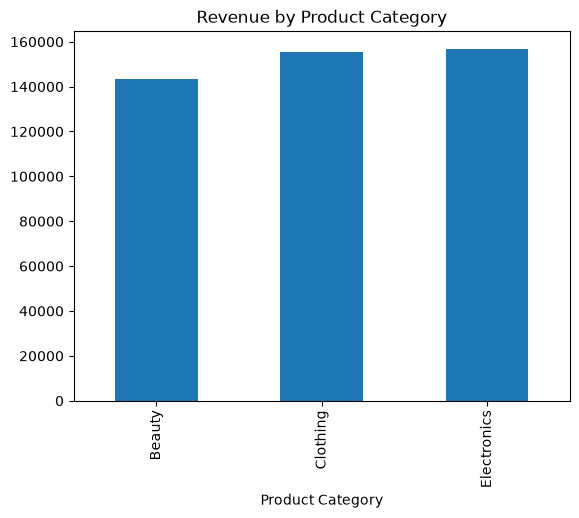

In [24]:
# Bar chart
category_sales.plot(kind="bar", title="Revenue by Product Category")
plt.show()


**Observation: Revenue by Product Category**

The chart shows that Electronics generated the highest revenue (approximately 157,000), followed closely by Clothing (approximately 156,000). Beauty generated the lowest revenue (approximately 143,000). All three categories contribute substantially to total revenue, although their revenue figures are not exactly equal. The business could investigate opportunities to improve Beauty category sales while maintaining the performance of Electronics and Clothing.

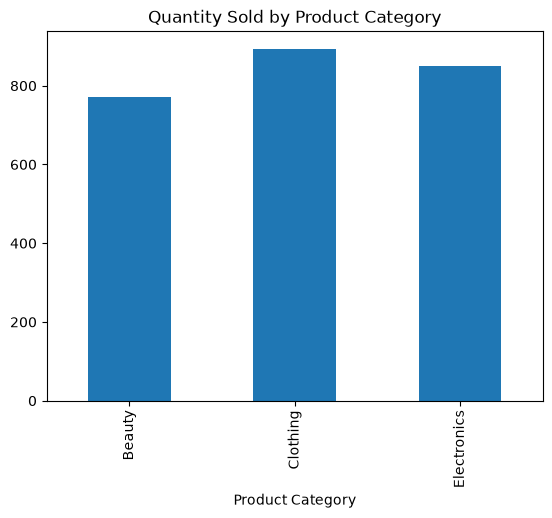

In [25]:
# Analyze the top-selling categories by quantity

category_quantity = df.groupby("Product Category")["Quantity"].sum()

category_quantity.plot(kind="bar", title="Quantity Sold by Product Category")
plt.show()


**Observation: Quantity Sold by Product Category**

The bar chart compares the total quantity sold across the three product categories. Clothing has the highest sales quantity, followed by Electronics, while Beauty has the lowest. Although Clothing sells the most units, Electronics generates the highest revenue according to the previous chart. This suggests that sales quantity and revenue do not necessarily follow the same pattern. The business could investigate ways to increase Beauty product sales while maintaining the performance of the other categories.


## 6. Correlation Heatmap


In [27]:

correlation = df[["Age", "Quantity", "Price per Unit", "Total Amount"]].corr()
correlation 




,Age,Quantity,Price per Unit,Total Amount
Age,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.060568,0.373707,0.851925,1.000000


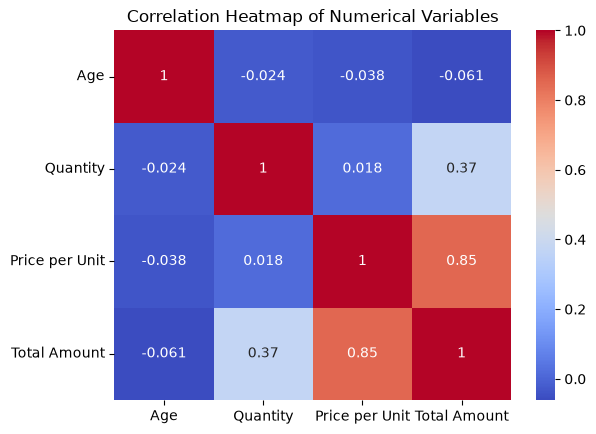

In [29]:
# Heatmap
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()


Observation : Correlation Heatmap

In chart, values closer to +1 indicate a stronger positive relationship, while values closer to −1 indicate a stronger negative relationship.

What does this tell us?
- Price per Unit and Total Amount: This is the strongest relationship in your heatmap. Higher unit prices tend to be associated with higher transaction amounts.
- Quantity and Total Amount: The positive correlation suggests that transactions with higher quantities tend to have higher total amounts.
- Age: Age has very weak correlations with the other numerical variables in this dataset.
BUT, correlation shows association, not proof that one variable causes another.

## 7. Additional Visualization

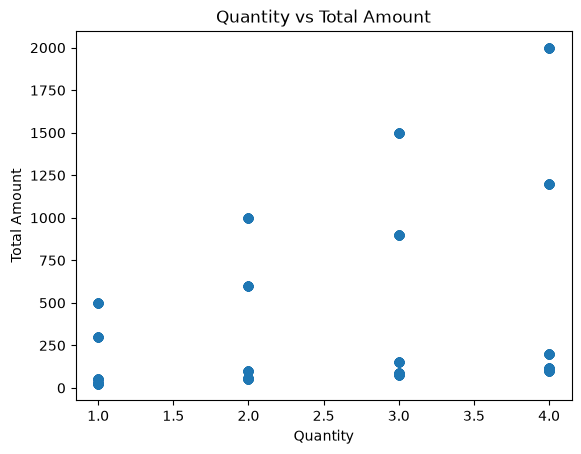

In [30]:
# Relationship Between Quantity and Total Amount

plt.scatter(df["Quantity"], df["Total Amount"])
plt.title("Quantity vs Total Amount")
plt.xlabel("Quantity")
plt.ylabel("Total Amount")
plt.show()



This chart will help us see how transaction amounts vary with the quantity purchased.

**Observation: Relationship Between Quantity and Total Amount**

The scatter plot shows a general positive relationship between quantity purchased and total transaction amount. Transactions with higher quantities can have higher total amounts, although considerable variation exists at each quantity level. This variation may be explained by differences in unit prices across transactions. The finding suggests that both quantity and unit price are important when analyzing sales revenue.

What does chart tell us?
- When customers buy more units, they can spend more money.
- Buying more units does not always mean spending more than every other customer, because product prices differ.
- Both the quantity purchased and the price per unit affect the total amount.


## 8. Conclusion and Business Recommendations


### Conclusion

This exploratory data analysis examined retail sales patterns, customer demographics, product categories, and relationships between numerical variables. Monthly and quarterly sales varied throughout the observed period, with the highest quarterly revenue recorded in Q4 2023. Electronics generated the highest revenue, while Clothing had the highest quantity sold. The correlation analysis showed a strong positive relationship between unit price and total transaction amount, along with a positive relationship between quantity and total amount.

### Business Recommendations

1. **Improve Beauty sales:** Offer discounts and special offers on Beauty products to attract more customers.
2. **Focus on popular categories:** Keep Electronics and Clothing products available because they generate good revenue and sales.
3. **Check sales regularly:** Compare monthly sales to understand which months have higher or lower sales and plan promotions accordingly.